## IEOR 4004: The Zombie Apocalypse Game (Section 1)

Leave the **Bunker**, visit the **Pharmacy**, **Hospital**, **Gas Station** and **Grocery Store**, and return
to the Bunker, travelling the minimum total distance. Intersections A–Q are optional.

**Rules:** (1) no street may be used twice, (2) no location may be passed through twice,
(3) use a TSP integer program from class, with MTZ *or* standard subtour elimination constraints.
The questions are in the handout.

In [1]:
# On Colab, uncomment the next line first (the free pip license is enough for this model size)
%pip install gurobipy networkx matplotlib
import networkx as nx
import matplotlib.pyplot as plt
import gurobipy as gp
from gurobipy import GRB, quicksum


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### The town

In [2]:
# ---- Section 1: Zombie Town data ----
# Node coordinates in feet
locations = {
    'Bunker': (0, 100),
    'Pharmacy': (450, 600),
    'Hospital': (550, 400),
    'GasStation': (450, 200),
    'Grocery': (200, 600),
    'A': (0, 0),
    'B': (0, 200),
    'C': (200, 0),
    'D': (200, 200),
    'E': (200, 400),
    'F': (200, 500),
    'G': (200, 700),
    'H': (450, 0),
    'I': (450, 400),
    'J': (450, 500),
    'K': (450, 700),
    'L': (650, 0),
    'M': (650, 400),
    'N': (650, 600),
    'O': (650, 700),
    'P': (950, 600),
    'Q': (950, 400),
}

# All arcs. Every two-way street appears in BOTH directions, (i, j) and (j, i).
edges = [
    ('Bunker', 'A'), ('A', 'Bunker'),
    ('Bunker', 'B'), ('B', 'Bunker'),
    ('A', 'C'), ('C', 'A'),
    ('B', 'D'), ('D', 'B'),
    ('C', 'D'), ('D', 'C'),
    ('C', 'H'), ('H', 'C'),
    ('D', 'E'), ('E', 'D'),
    ('E', 'I'), ('I', 'E'),
    ('E', 'F'), ('F', 'E'),
    ('F', 'J'), ('J', 'F'),
    ('F', 'Grocery'), ('Grocery', 'F'),
    ('Grocery', 'G'), ('G', 'Grocery'),
    ('G', 'K'), ('K', 'G'),
    ('K', 'O'), ('O', 'K'),
    ('K', 'Pharmacy'), ('Pharmacy', 'K'),
    ('Pharmacy', 'N'), ('N', 'Pharmacy'),
    ('Pharmacy', 'J'), ('J', 'Pharmacy'),
    ('J', 'I'), ('I', 'J'),
    ('Hospital', 'M'), ('M', 'Hospital'),
    ('I', 'Hospital'), ('Hospital', 'I'),
    ('I', 'GasStation'), ('GasStation', 'I'),
    ('GasStation', 'H'), ('H', 'GasStation'),
    ('H', 'L'), ('L', 'H'),
    ('L', 'M'), ('M', 'L'),
    ('M', 'Q'), ('Q', 'M'),
    ('Q', 'P'), ('P', 'Q'),
    ('P', 'N'), ('N', 'P'),
    ('N', 'M'), ('M', 'N'),
    ('N', 'O'), ('O', 'N'),
]

# Length of each arc = Manhattan distance between its endpoints (all streets run N-S or E-W)
dist = {(i, j): abs(locations[i][0] - locations[j][0]) + abs(locations[i][1] - locations[j][1])
        for (i, j) in edges}

depot    = "Bunker"
required = ["Bunker", "Pharmacy", "Hospital", "GasStation", "Grocery"]
nodes    = list(locations)
n        = len(nodes)
print(f"{n} nodes, {len(edges)} arcs")

22 nodes, 58 arcs


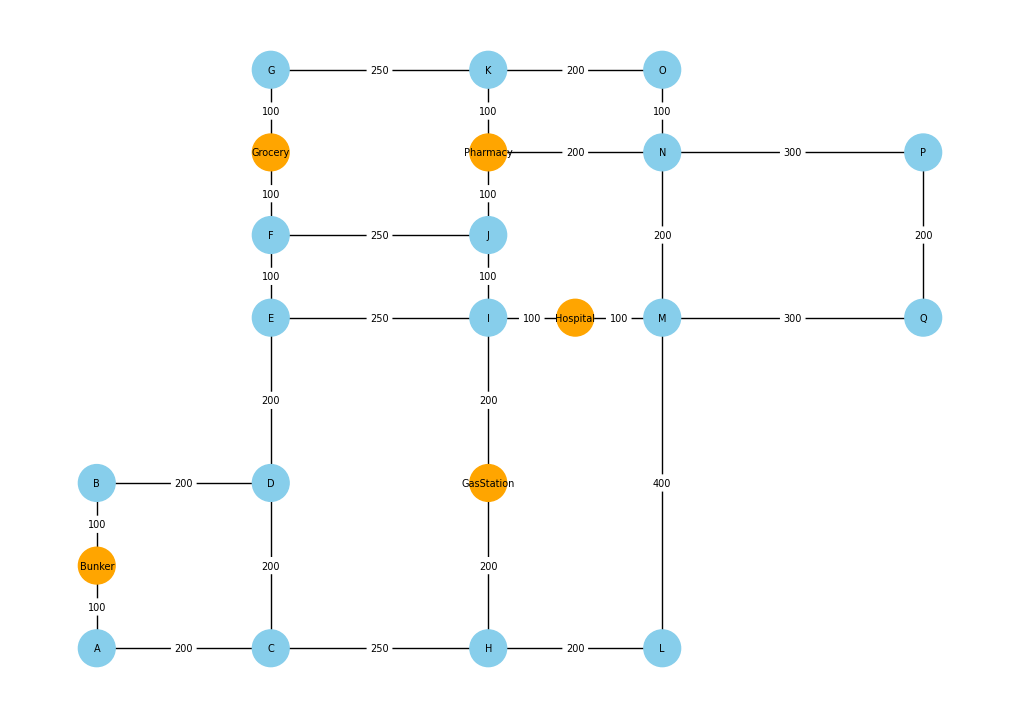

In [3]:
G = nx.Graph()
G.add_edges_from(edges)

def draw_map(route_arcs=None):
    plt.figure(figsize=(10, 7))
    colors = ["orange" if i in required else "skyblue" for i in G.nodes]
    nx.draw(G, locations, with_labels=True, node_color=colors, node_size=700, font_size=7)
    nx.draw_networkx_edge_labels(G, locations, edge_labels={e: dist[e] for e in G.edges},
                                 font_size=7, rotate=False)
    if route_arcs:   # highlight the route in red, with arrows showing the direction
        nx.draw_networkx_edges(nx.DiGraph(route_arcs), locations, edge_color="crimson",
                               width=3, arrowsize=20, node_size=700)
    plt.show()

draw_map()

### Question 2: the Gurobi model

In [12]:
m = gp.Model("zombie_tsp")
x = m.addVars(edges, vtype=GRB.BINARY, name="x")   # x[i, j] = 1 if the route goes i -> j
m.setObjective(quicksum(dist[i, j] * x[i, j] for (i, j) in edges), GRB.MINIMIZE)

for i in nodes:
    out_flow = quicksum(x[i, j] for j in nodes if (i, j) in edges)
    in_flow  = quicksum(x[j, i] for j in nodes if (j, i) in edges)
    if i in required:
        m.addConstr(out_flow == 1)
        m.addConstr(in_flow == 1)
    else:
        m.addConstr(out_flow == in_flow)
        m.addConstr(out_flow <= 1)
        
# No street may be used twice
for i, j in G.edges():
    m.addConstr(x[i, j] + x[j, i] <= 1)

Add subtour elimination with **one** of the two options (run only one of the next two cells).

In [15]:
# Option A: MTZ
u = m.addVars(nodes, lb=1, ub=n - 1, name="u")
for (i, j) in edges:
    if i != depot and j != depot:
        m.addConstr(u[i] - u[j] + (n-1)*x[i, j] <= n-2)

In [10]:
# Option B: standard subtour elimination, one constraint per cycle that avoids the Bunker
cycles = {frozenset(cy) for cy in nx.simple_cycles(nx.DiGraph(edges)) if depot not in cy}
for S in cycles:
    pass  # TODO: subtour elimination constraint for node set S

Solve and look at the route.

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G325)

CPU model: Apple M2
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 127 rows, 102 columns and 383 nonzeros (Min)
Model fingerprint: 0xda0bb54b
Model has 58 linear objective coefficients
Variable types: 44 continuous, 58 integer (58 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [1e+02, 4e+02]
  Bounds range     [1e+00, 2e+01]
  RHS range        [1e+00, 2e+01]

MIP start from previous solve produced solution with objective 2700 (0.00s)
Loaded MIP start from previous solve with objective 2700

Presolve removed 127 rows and 102 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.01 seconds (0.00 work units)
Thread count was 1 (of 8 available processors)

Solution count 1: 2700 

Optimal solution found (tolerance 1.00e-04)
Best objective 2.700000000000e+03,

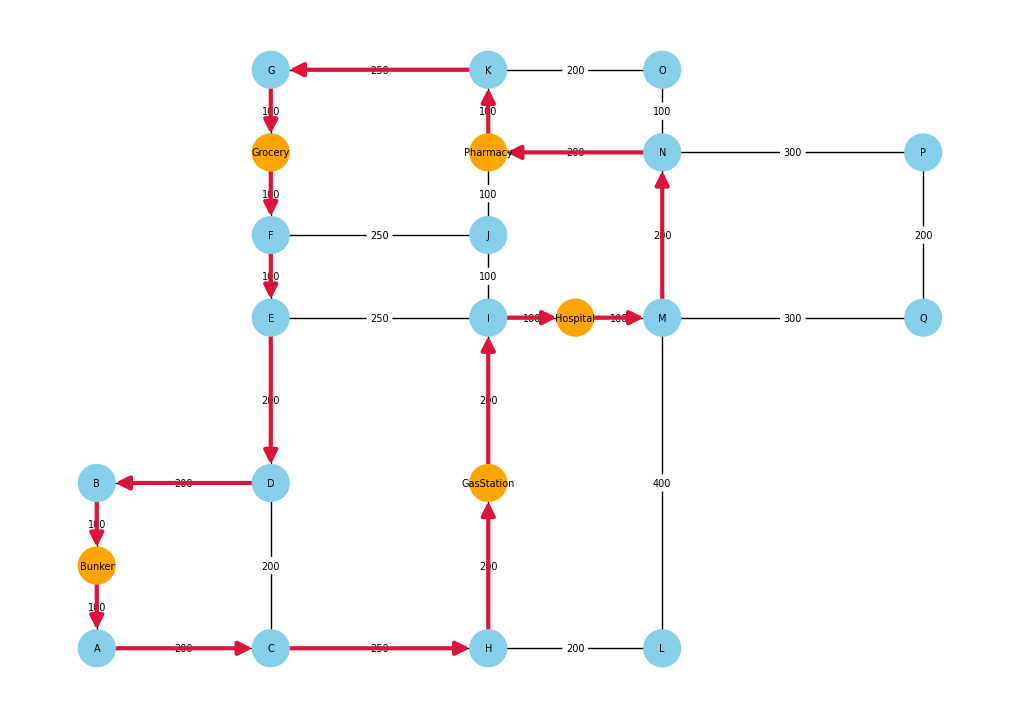

In [16]:
m.optimize()
route_arcs = [(i, j) for (i, j) in edges if x[i, j].X > 0.5]
print(f"Total distance: {m.ObjVal:,.0f} ft")
print("Arcs used:", route_arcs)
draw_map(route_arcs)

**Infeasible?** Find a minimal set of conflicting constraints (give your constraints names with
`name=...` so the output is readable):
```python
if m.status == GRB.INFEASIBLE:
    m.computeIIS()
    for con in m.getConstrs():
        if con.IISConstr:
            print(con.ConstrName)
```

In [17]:
# Reconstruct the ordered route
successor = {i: j for i, j in route_arcs}
route = [depot]

while True:
    next_node = successor[route[-1]]
    route.append(next_node)
    if next_node == depot:
        break

print("Optimal route:")
print(" -> ".join(route))
print(f"Total distance: {m.ObjVal:.0f} ft")


Optimal route:
Bunker -> A -> C -> H -> GasStation -> I -> Hospital -> M -> N -> Pharmacy -> K -> G -> Grocery -> F -> E -> D -> B -> Bunker
Total distance: 2700 ft


### Question 3 (optional): what if streets could be reused?
`nx.shortest_path_length(G, i, j, weight=...)` gives the shortest distance between two nodes and
`nx.shortest_path(...)` gives the path itself. (Store the lengths on `G` first, e.g.
`nx.set_edge_attributes(G, {e: dist[e] for e in G.edges}, "length")`, then use `weight="length"`.)